In [1]:
## a useful function to generate a data list for further analysis
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from curate_trackball_database import create_curated_dataset
from analyse_stimulus_evoked_response import main


In [3]:
##need to add this additional cell because useful tools are in another folder. Need to integrate these two folders one day
import sys
sys.path.insert(0, 'C:/Users/neuroPC/Documents/GitHub/behavioral_analysis')
from useful_tools import select_animals_gpt

In [4]:
json_file = "./analysis_methods_dictionary.json"
with open(json_file, "r") as f:
    analysis_methods = json.loads(f.read())
    
Datasets="Z:/DATA/experiment_trackball_Optomotor"
thisDataset = f"{Datasets}/"


In [5]:
analysis_methods

{'experiment_name': 'dots',
 'overwrite_curated_dataset': True,
 'graph_colour_code': ['r', 'y', 'm', 'c', 'k', 'b', 'g', 'r'],
 'debug_mode': False,
 'filtering_method': 'sg_filter',
 'plotting_tbt_overview': False,
 'plotting_trajectory': False,
 'plotting_event_related_trajectory': False,
 'plotting_optomotor_response': True,
 'load_experiment_condition_from_database': True,
 'select_animals_by_condition': True}

In [3]:
## this cell searches for a folder with a specified experiment_name under the dataset path and list up all the csv file in that folder.
## In this project, we usually have one csv file in that folder so there is no confusion
dir_list = []
file_type=".csv"
for root, dirs, files in os.walk(thisDataset):
    if analysis_methods.get("experiment_name") in root.split(
        os.path.sep
    ):  ## add this condition to avoid data from other experiments
        if any(name.endswith(file_type) for name in files):
            dir_list.append(root.replace("\\", "/"))


print(f"these directories are found {dir_list}")

these directories are found ['Z:/DATA/experiment_trackball_Optomotor/L22006/220728/dots', 'Z:/DATA/experiment_trackball_Optomotor/L22006/220728/dots/data', 'Z:/DATA/experiment_trackball_Optomotor/L22006/220728/dots/sonstiges', 'Z:/DATA/experiment_trackball_Optomotor/L22007/220728/dots', 'Z:/DATA/experiment_trackball_Optomotor/L22007/220728/dots/data', 'Z:/DATA/experiment_trackball_Optomotor/L22007/220728/dots/sonstiges', 'Z:/DATA/experiment_trackball_Optomotor/L22008/220728/dots', 'Z:/DATA/experiment_trackball_Optomotor/L22008/220728/dots/data', 'Z:/DATA/experiment_trackball_Optomotor/L22008/220728/dots/sonstiges', 'Z:/DATA/experiment_trackball_Optomotor/L22009/220803/dots', 'Z:/DATA/experiment_trackball_Optomotor/L22009/220803/dots/data', 'Z:/DATA/experiment_trackball_Optomotor/L22009/220803/dots/sonstige', 'Z:/DATA/experiment_trackball_Optomotor/L22010/220803/dots', 'Z:/DATA/experiment_trackball_Optomotor/L22010/220803/dots/data', 'Z:/DATA/experiment_trackball_Optomotor/L22010/220803

In [ ]:
## go through each file in the list
for thisDir in dir_list:
    p_name = "database_curated.pickle"
    thisPickle = os.path.join(thisDir, p_name)
    if "archive" in thisDir:
        print(f"skip archive folder for {thisDir}")
        continue
    ## check if H5 file, the curated dataset, exists or not, if not we assume this is the first time to analyse this data. 
    ## Then the raw data will be processed regardless whether overwrite_curated_dataset is true or not
    if os.path.isfile(thisPickle):
        if analysis_methods.get("overwrite_curated_dataset") == True:
            print(f"re analyse and update dataset {thisPickle}")
            create_curated_dataset(thisDir, analysis_methods)
        else:
            print(f"do not re analyse dataset {thisPickle},skip this file")
            continue
    else:
        print(f"first time to create this file {thisPickle}")
        create_curated_dataset(thisDir, analysis_methods)

In [8]:
# Define the path to your Excel file
dir_list = []
file_type=".pickle"
using_google_sheet=True
sheet_name = "VCCball"
experiment_name=analysis_methods.get("experiment_name")
if analysis_methods.get("load_experiment_condition_from_database") == True:
    if using_google_sheet==True:
        database_id = "1UL4eEUrQMapx9xz11-IyOSlPBcep1I9vBJ2uGgVudb8"
                #https://docs.google.com/spreadsheets/d/1UL4eEUrQMapx9xz11-IyOSlPBcep1I9vBJ2uGgVudb8/edit?usp=sharing
        url = f"https://docs.google.com/spreadsheets/d/{database_id}/gviz/tq?tqx=out:csv&sheet={sheet_name}"
        #df = pd.read_excel(url, engine='openpyxl')## use this function if the file is not google sheet but uploaded excel file

        df = pd.read_csv(url)
    else:
        excel_file_path = "Z:/DATA/experiment_trackball_Optomotor/Locusts Management.xlsx"
        print(f"using a database {excel_file_path} from the server but this file might be outdated")
        # Create a 'with' statement to open and read the Excel file
        with pd.ExcelFile(excel_file_path) as xls:
            # Read the Excel sheet into a DataFrame with the sheet name (folder name)
            df = pd.read_excel(xls, sheet_name)
        ##list up the conditions and answers as strings for input argument to select animal. One condition must pair with one answer
    if analysis_methods.get("select_animals_by_condition") == True:
        animal_of_interest=select_animals_gpt(df,"Stimulus Type (list up all the stimulus paradigm this animal receive)","dots")
    else:
        animal_of_interest=df
    ID_array=animal_of_interest["ID"].values
    dir_list = [
    root.replace("\\", "/")
    for root, dirs, files in os.walk(thisDataset)
    if any(ID in root for ID in ID_array)
    and experiment_name in root.split(os.path.sep)
    and any(name.endswith(file_type) for name in files)
]
else:
    ## this cell searches for a folder with a specified experiment_name under the dataset path and list up all the hdf5 file in that folder.
    ## However,some changes need to be made once we do sleap or deeplabcut where there are more than one H5 file generated
    for root, dirs, files in os.walk(thisDataset):
        if analysis_methods.get("experiment_name") in root.split(os.path.sep):## add this condition to avoid data from other experiments
            if any(name.endswith(file_type) for name in files):
                dir_list.append(root.replace("\\", "/"))

In [9]:
dir_list

['Z:/DATA/experiment_trackball_Optomotor/L22146/221106/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L22147/221106/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L22148/221106/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L22149/221106/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L22150/221106/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L22151/221106/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L22152/221106/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L23035/230824/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L23036/230824/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L23037/230824/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L23038/230824/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L23039/230824/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L23040/230824/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L23041/230824/dots',
 'Z:/DATA/experiment_trackball_Optomotor/L23042/230824/dots']

ready to plot graph with some data


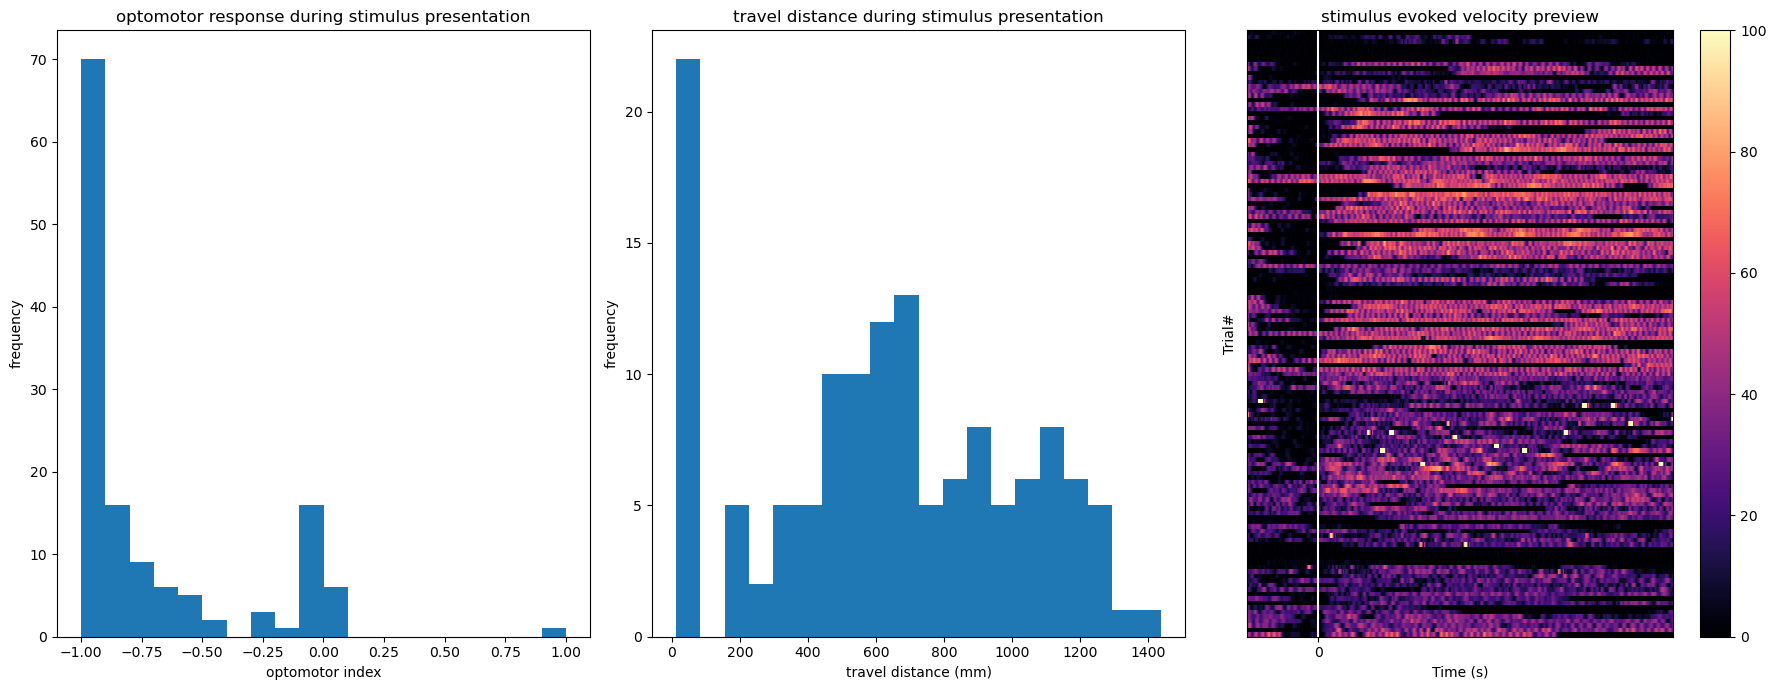

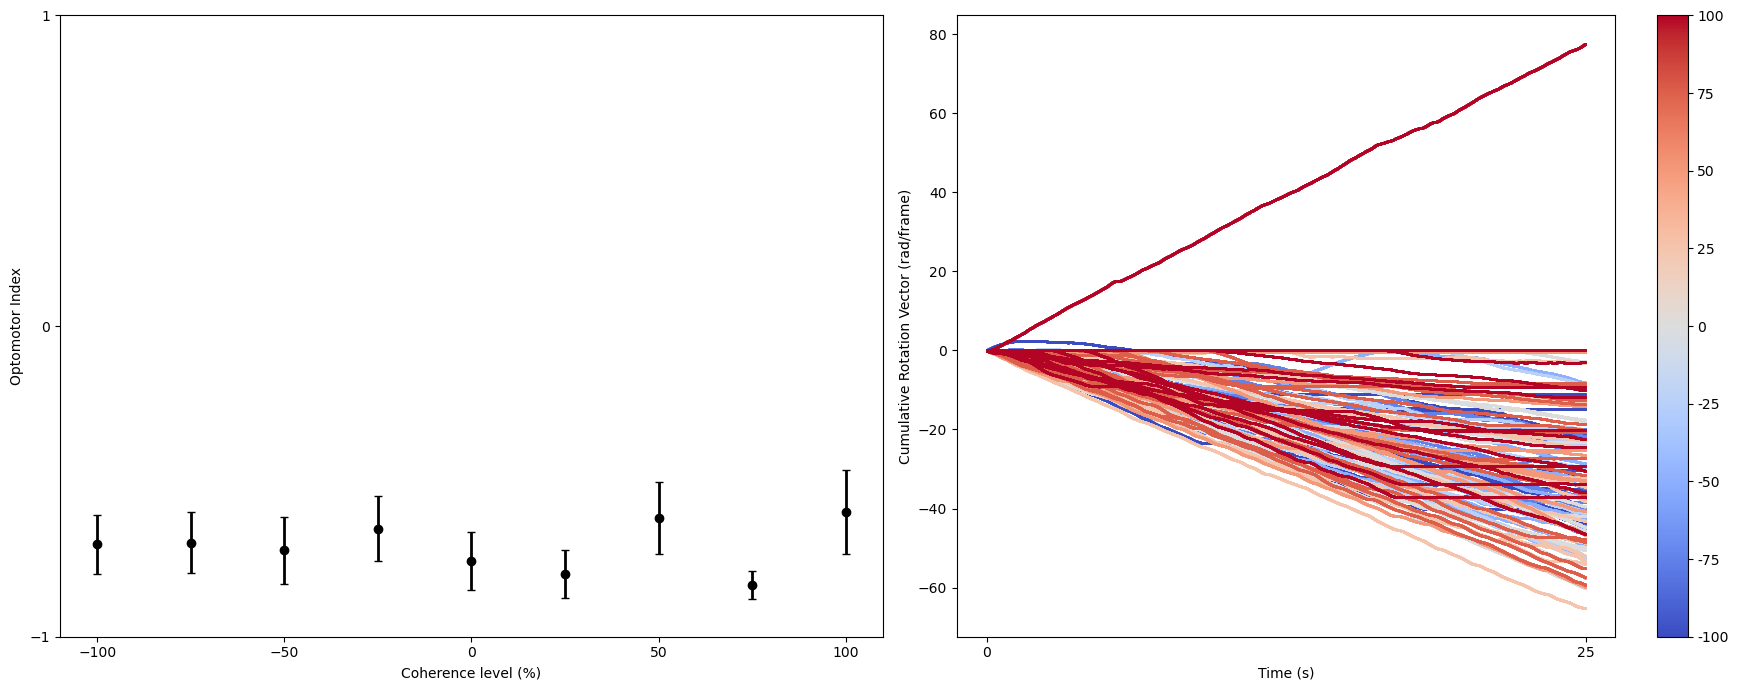

ready to plot graph with some data


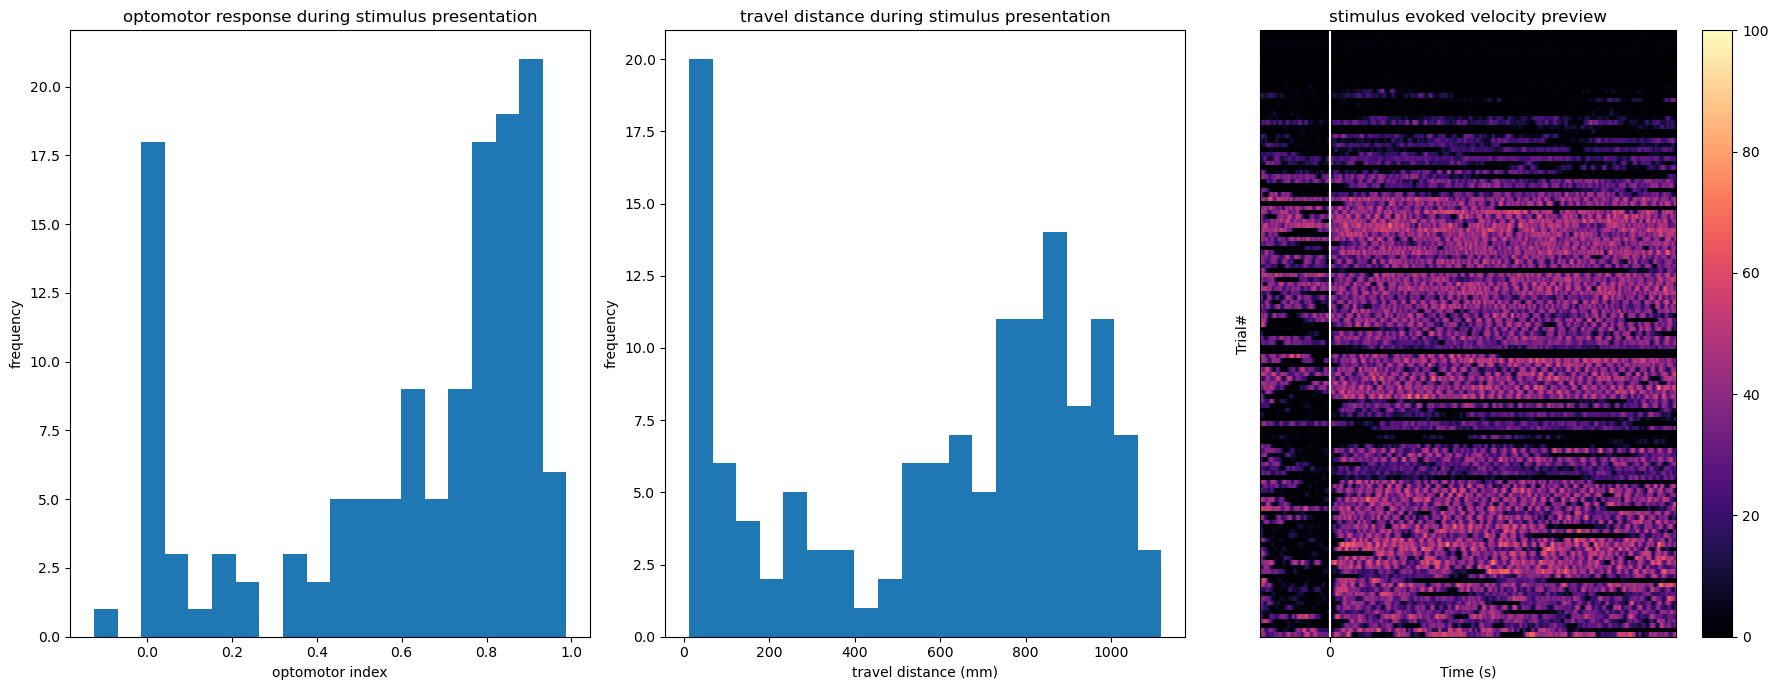

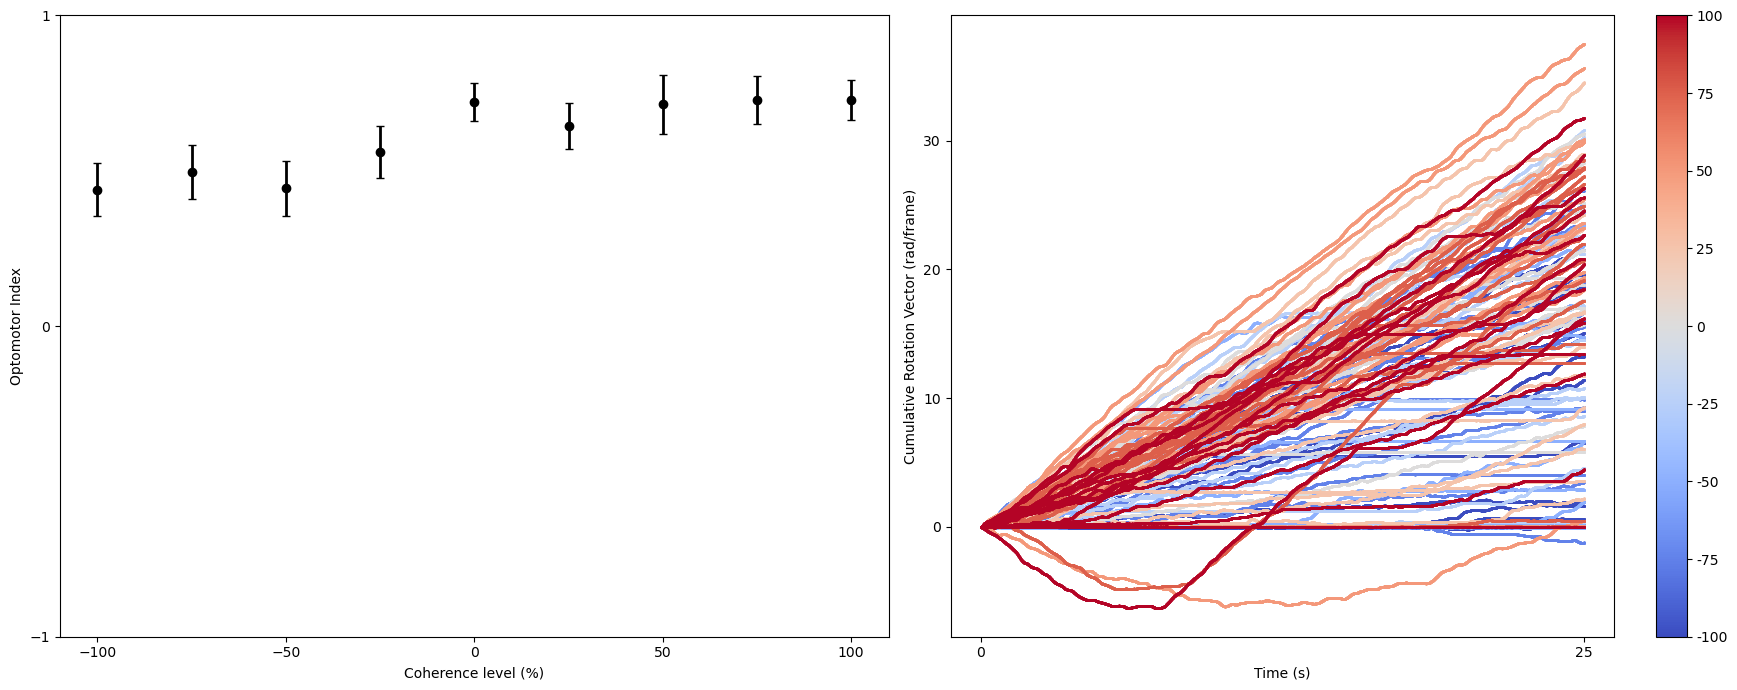

ready to plot graph with some data


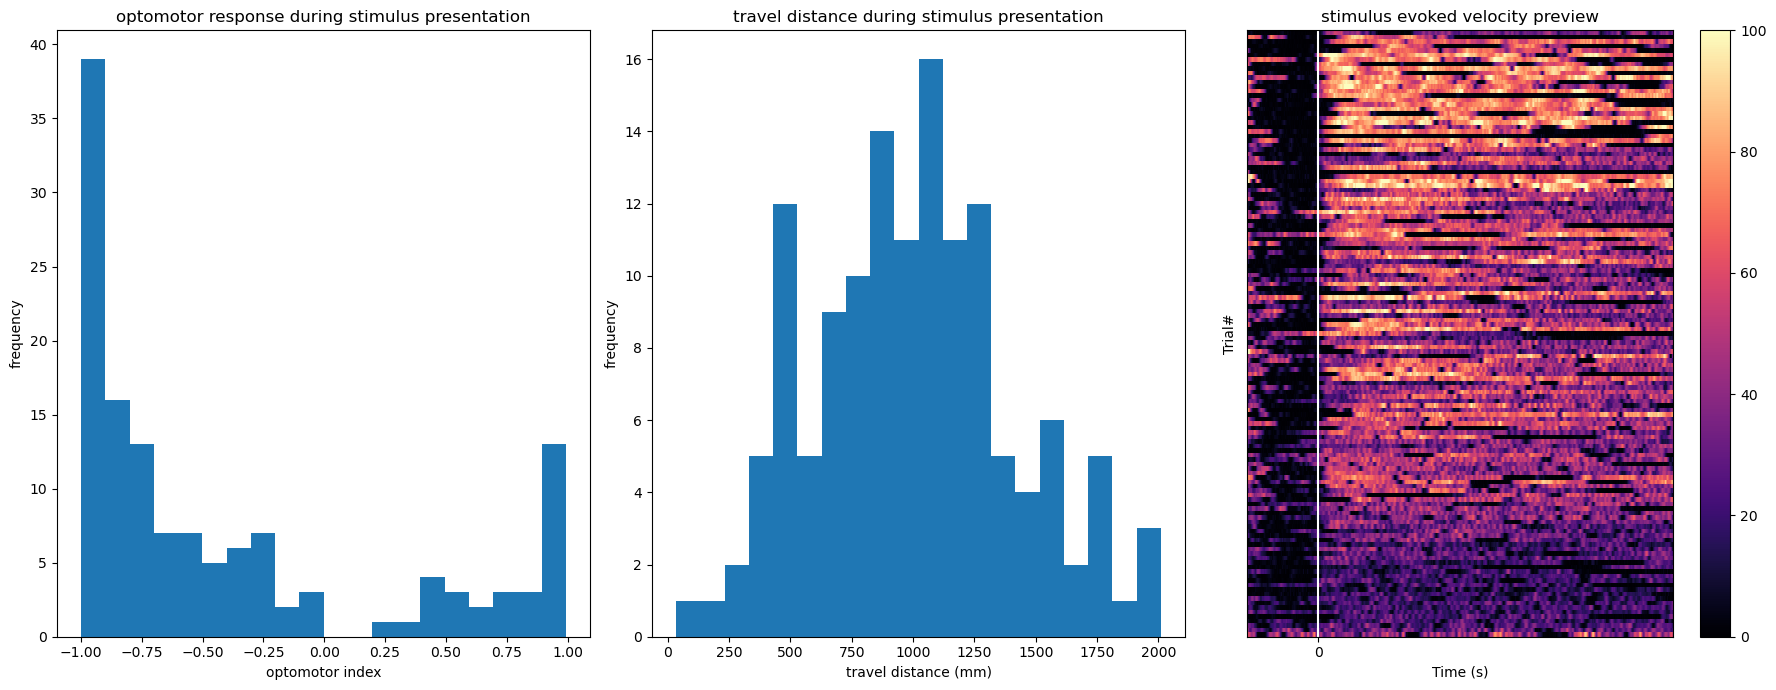

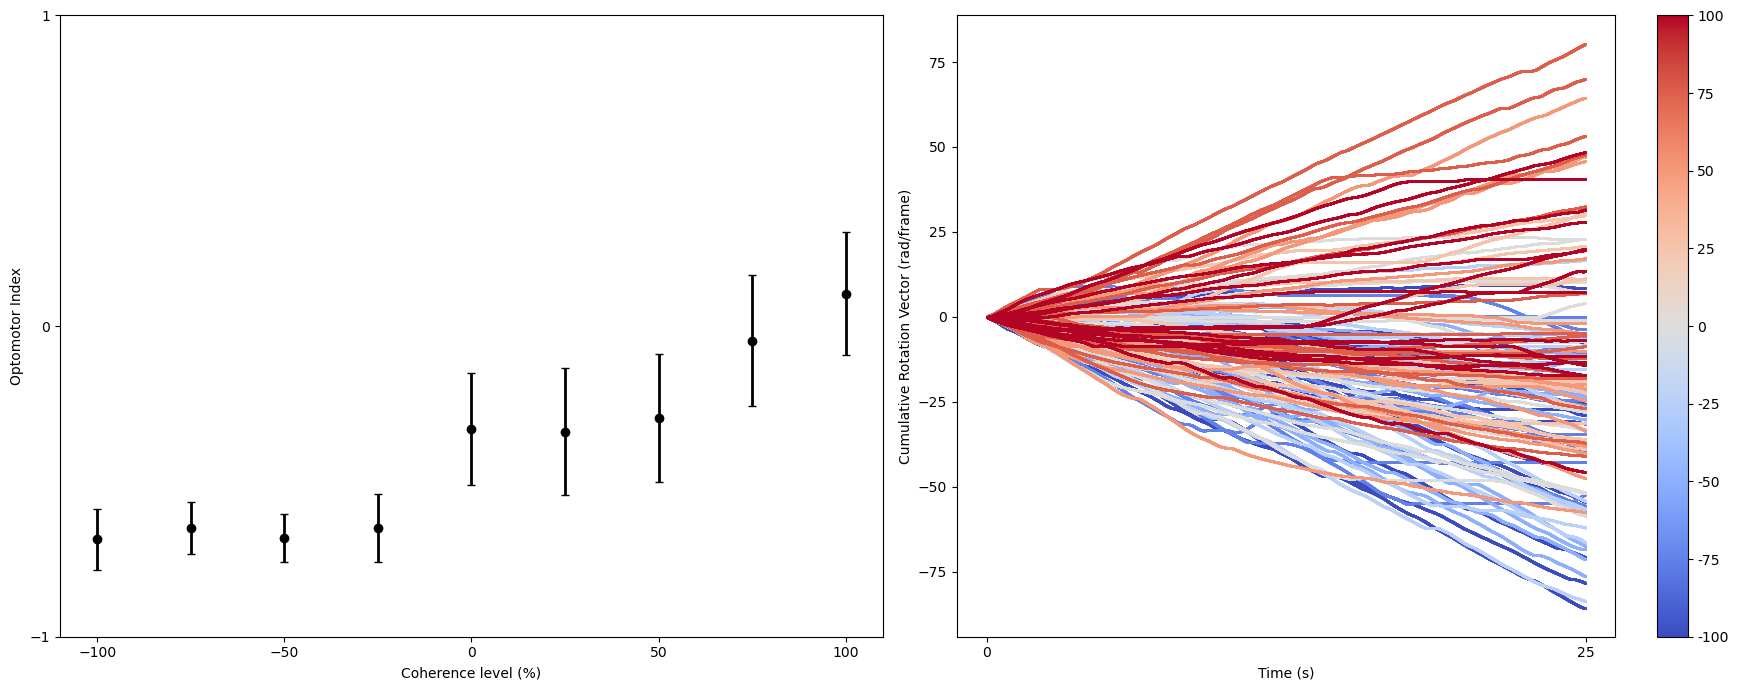

ready to plot graph with some data


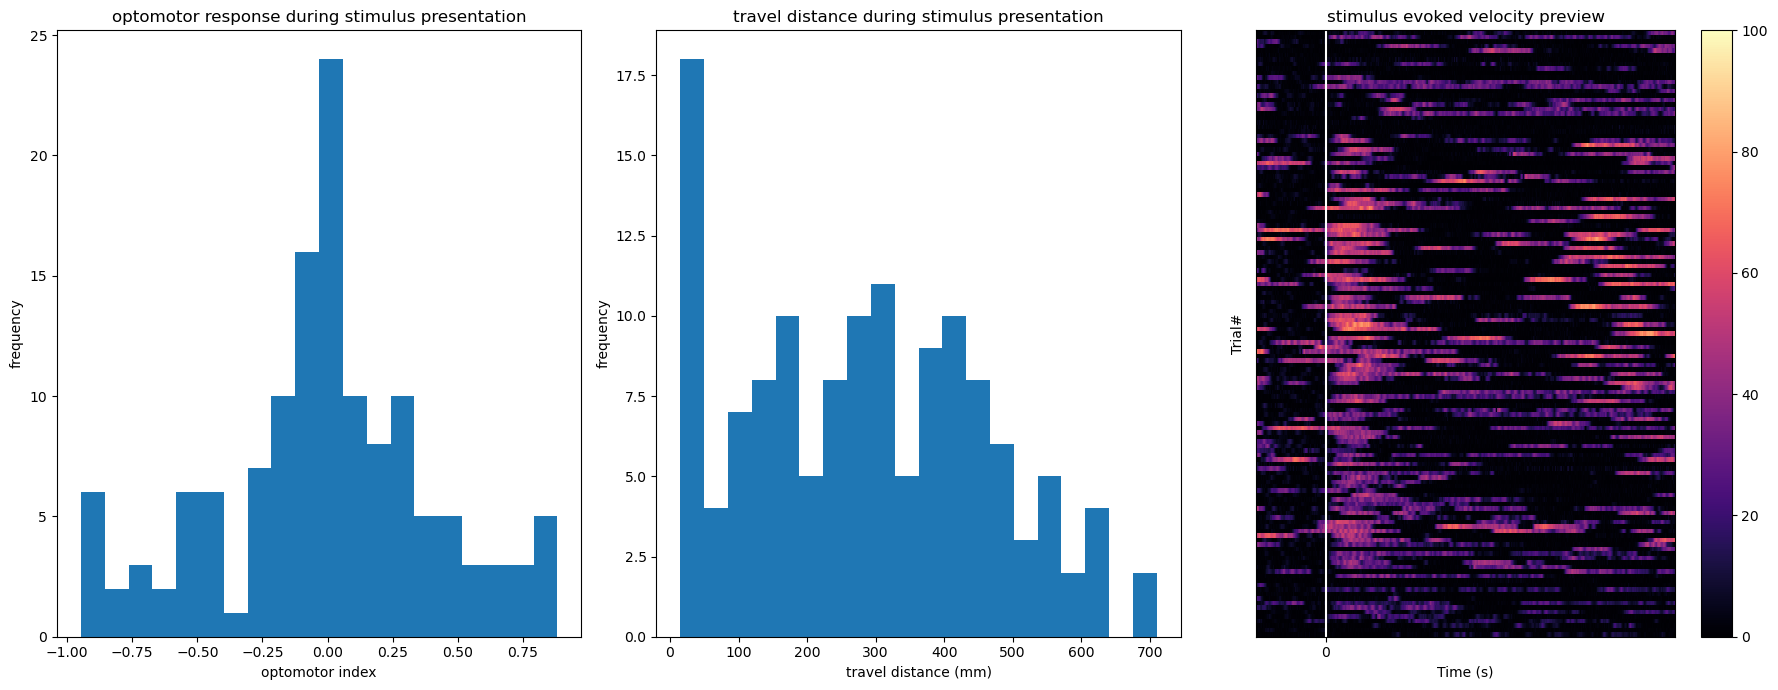

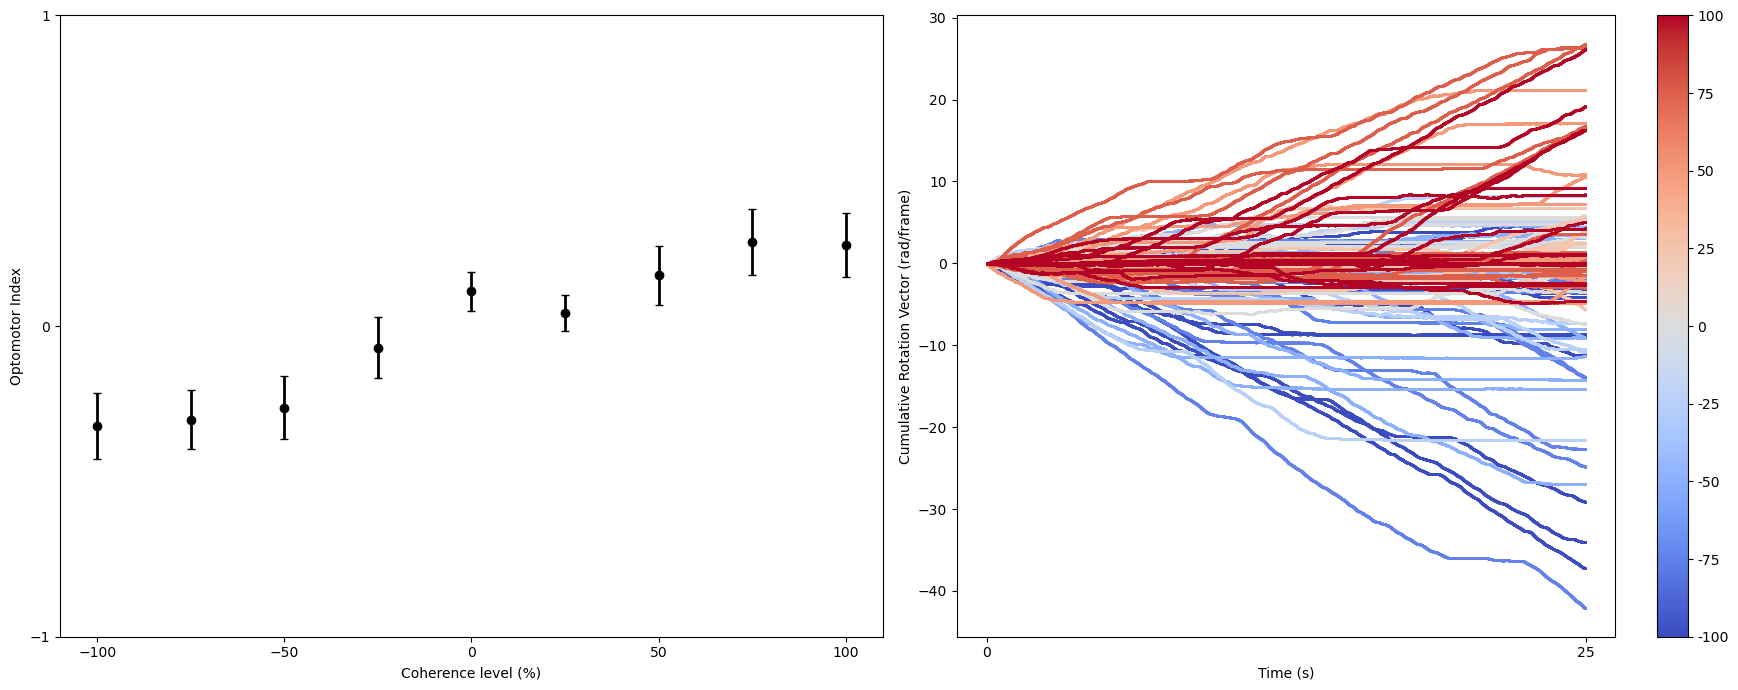

ready to plot graph with some data


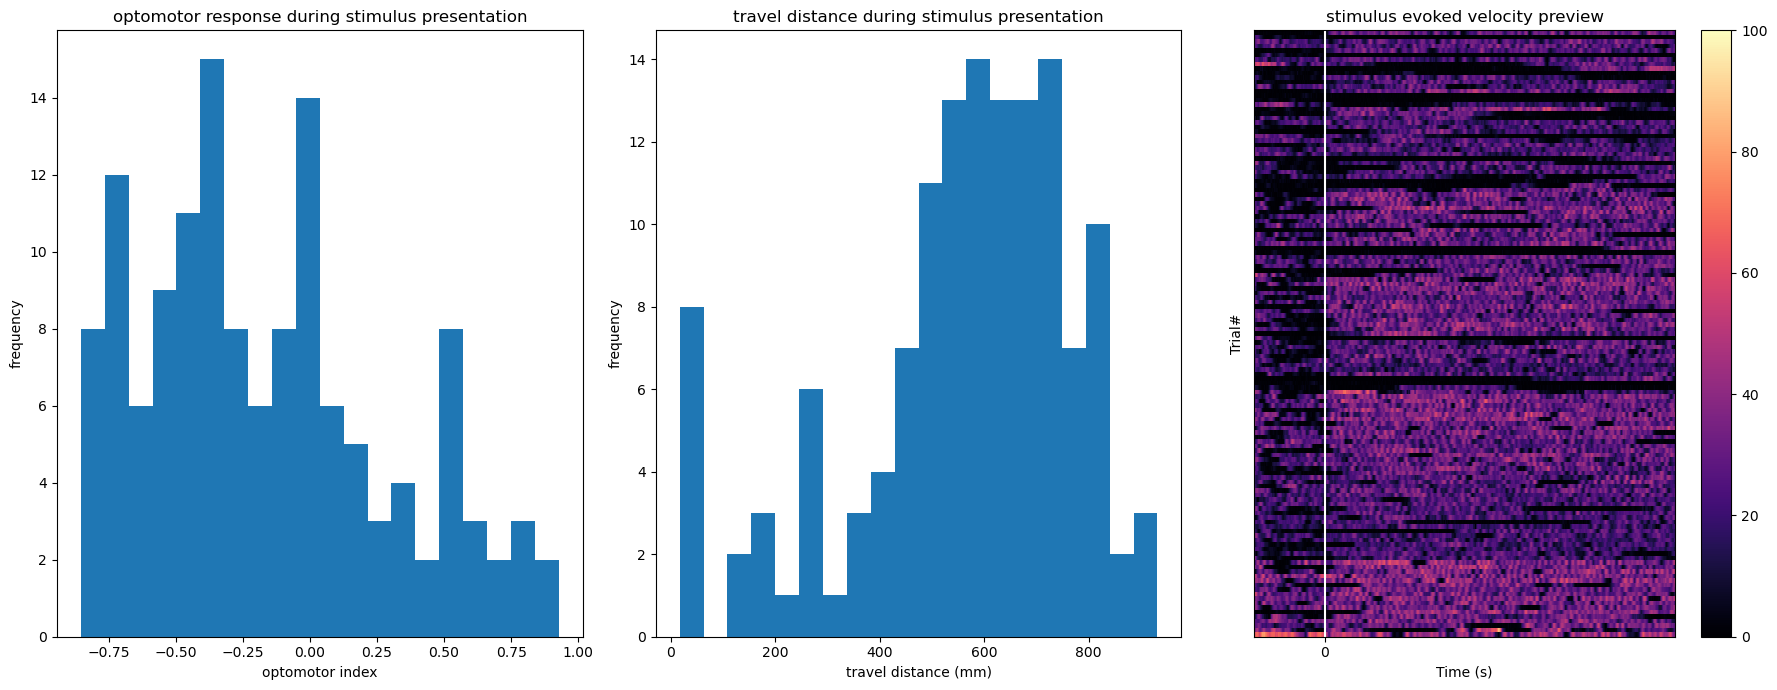

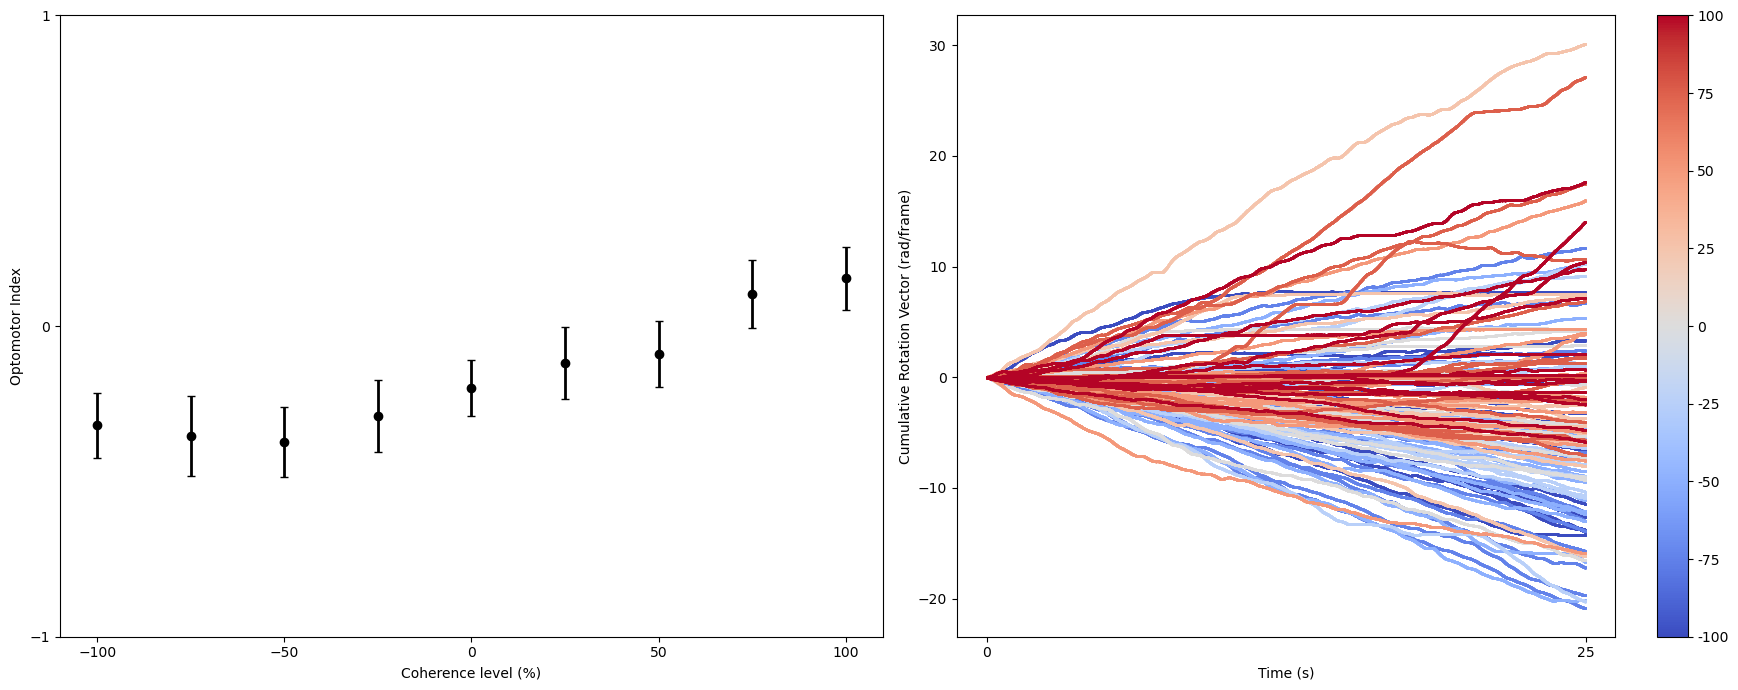

ready to plot graph with some data


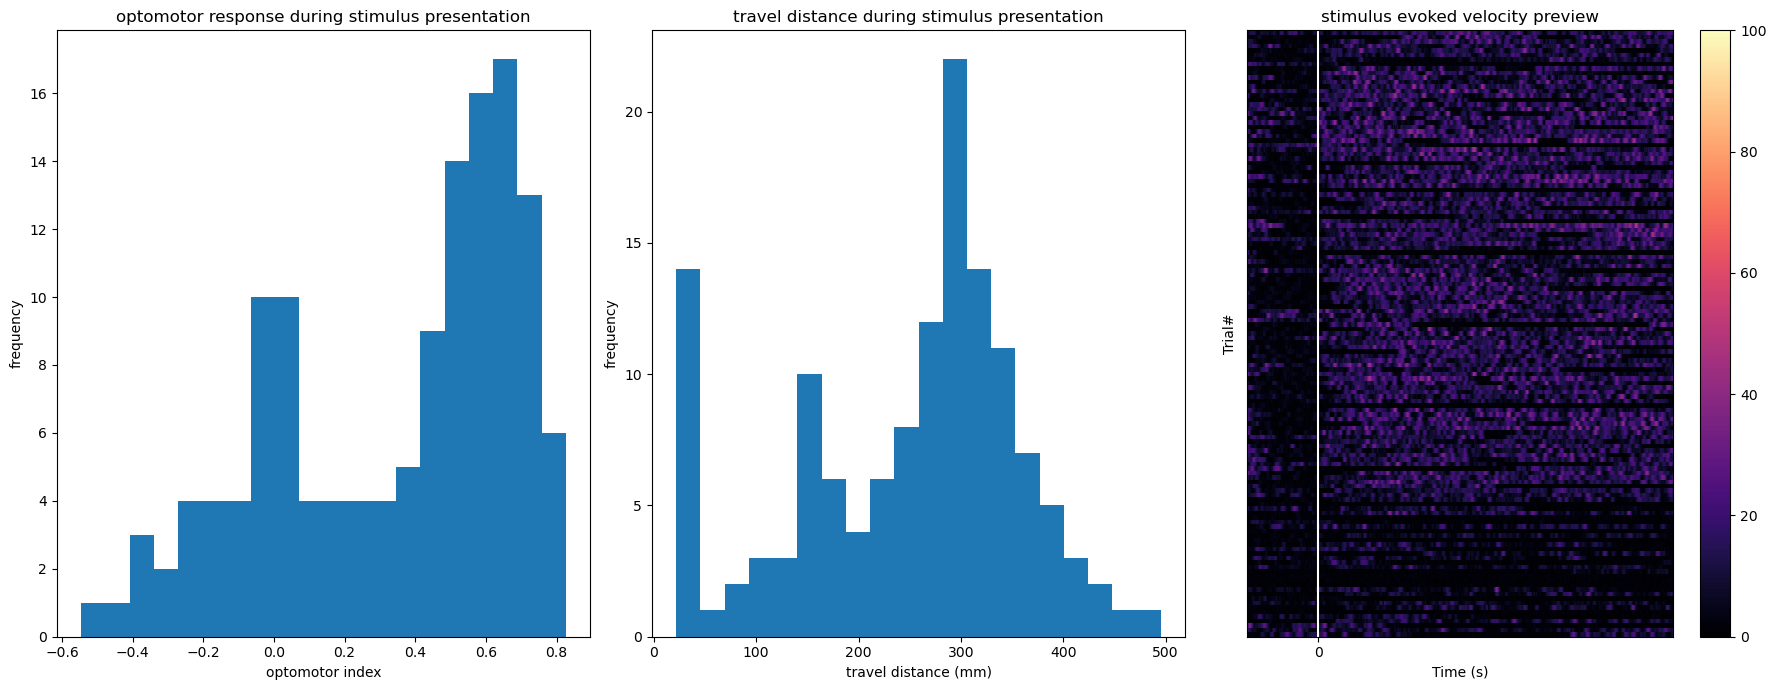

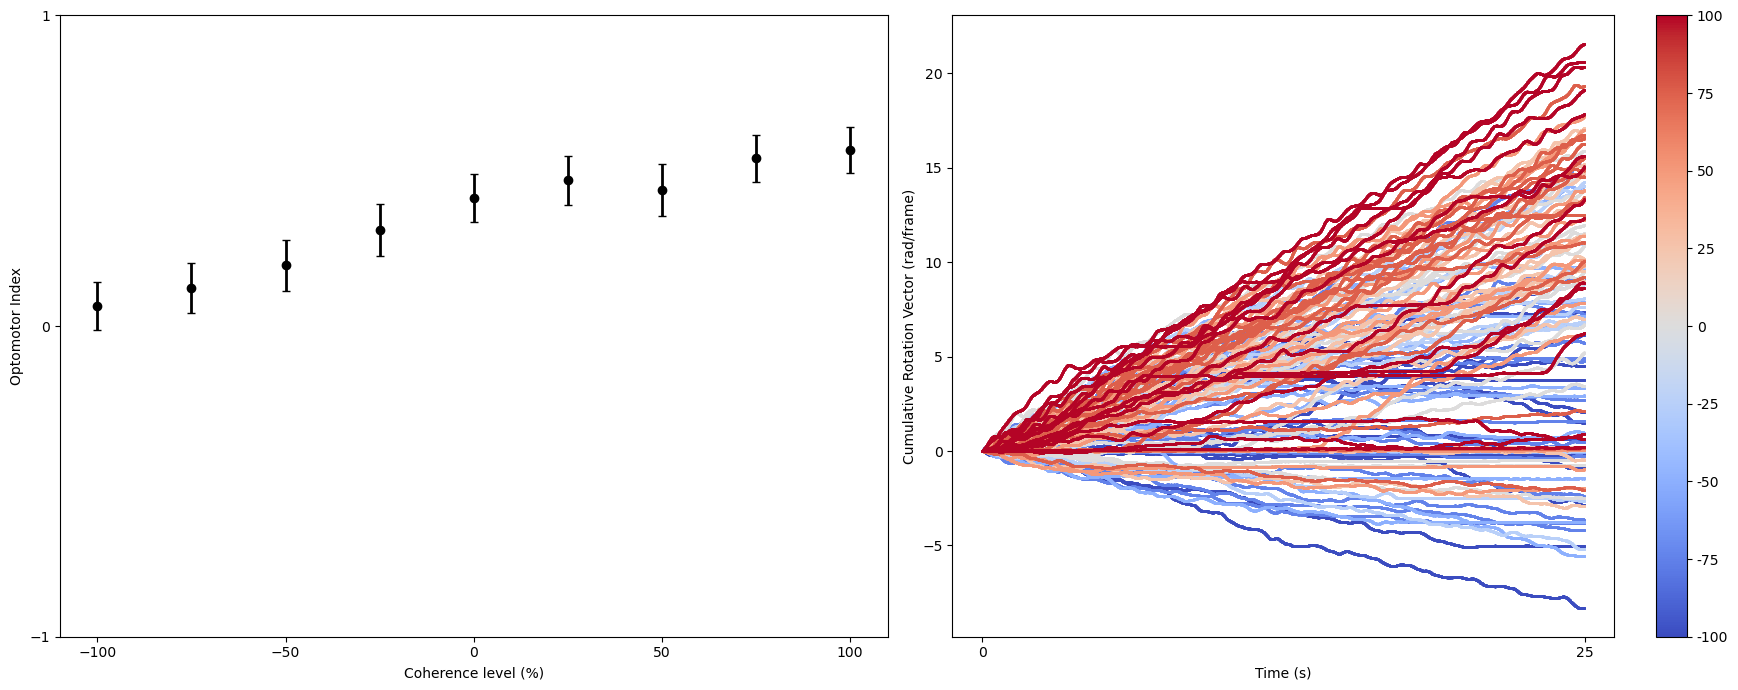

ready to plot graph with some data


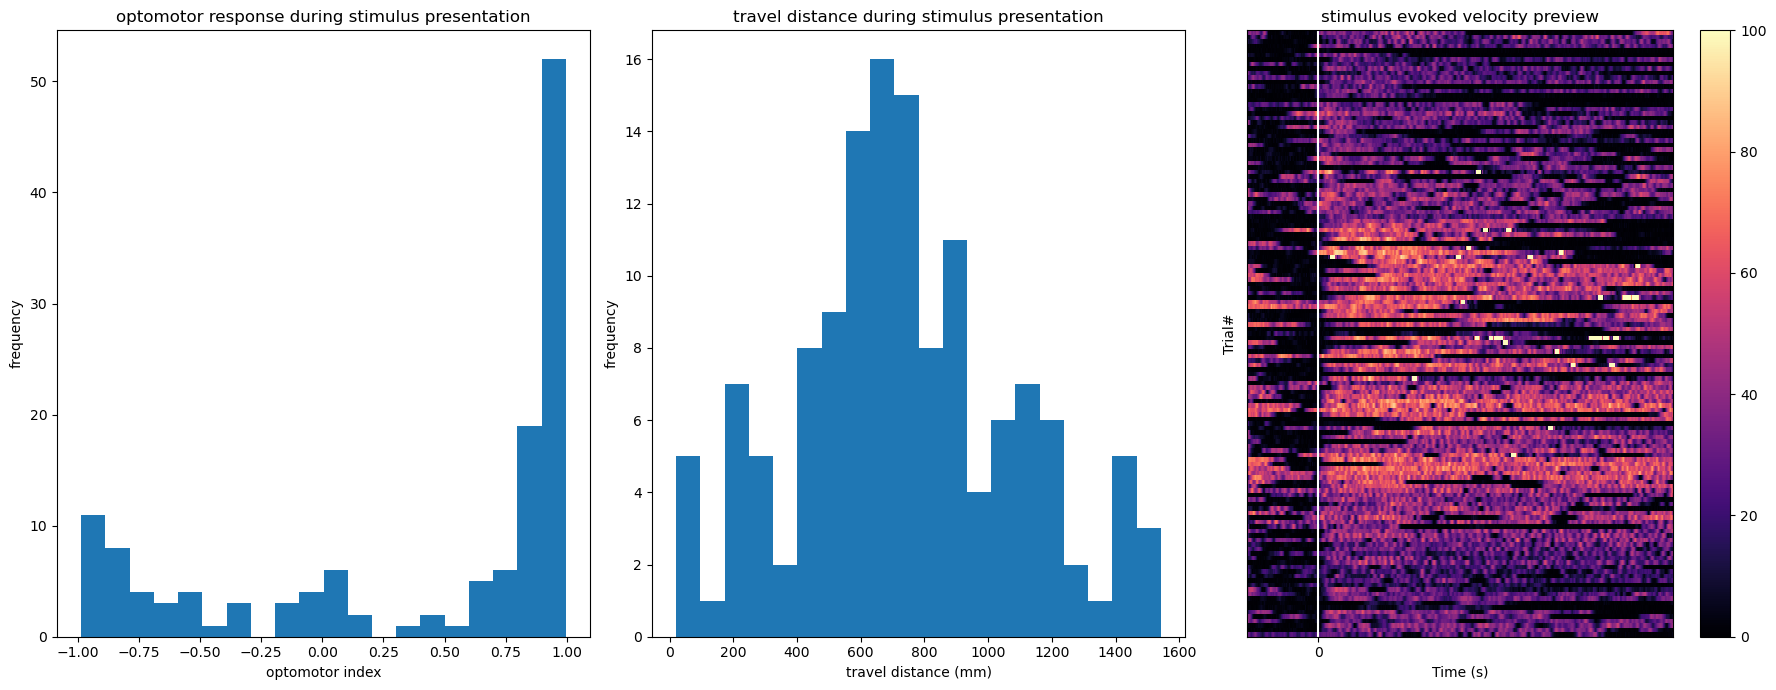

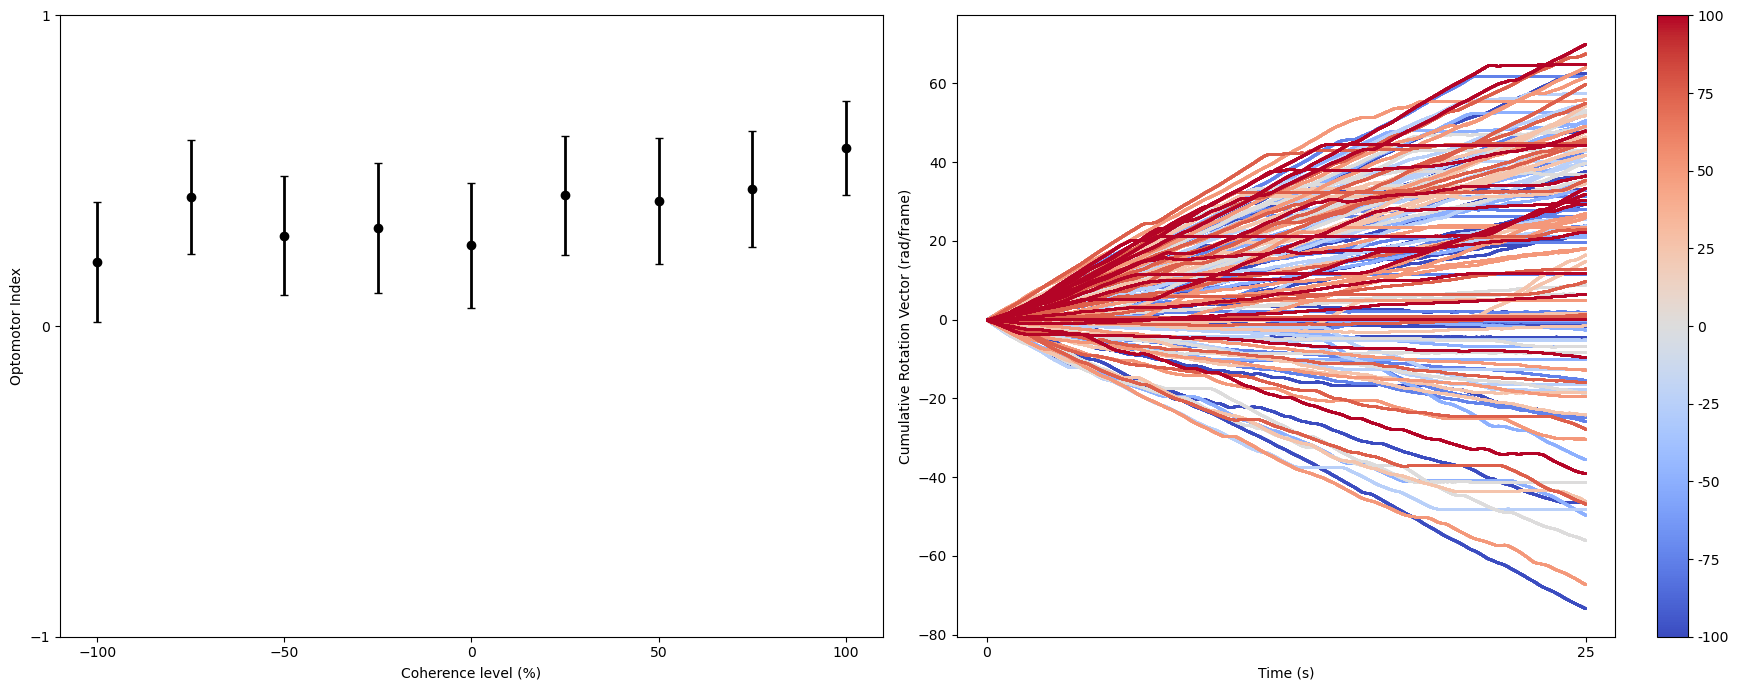

ready to plot graph with some data


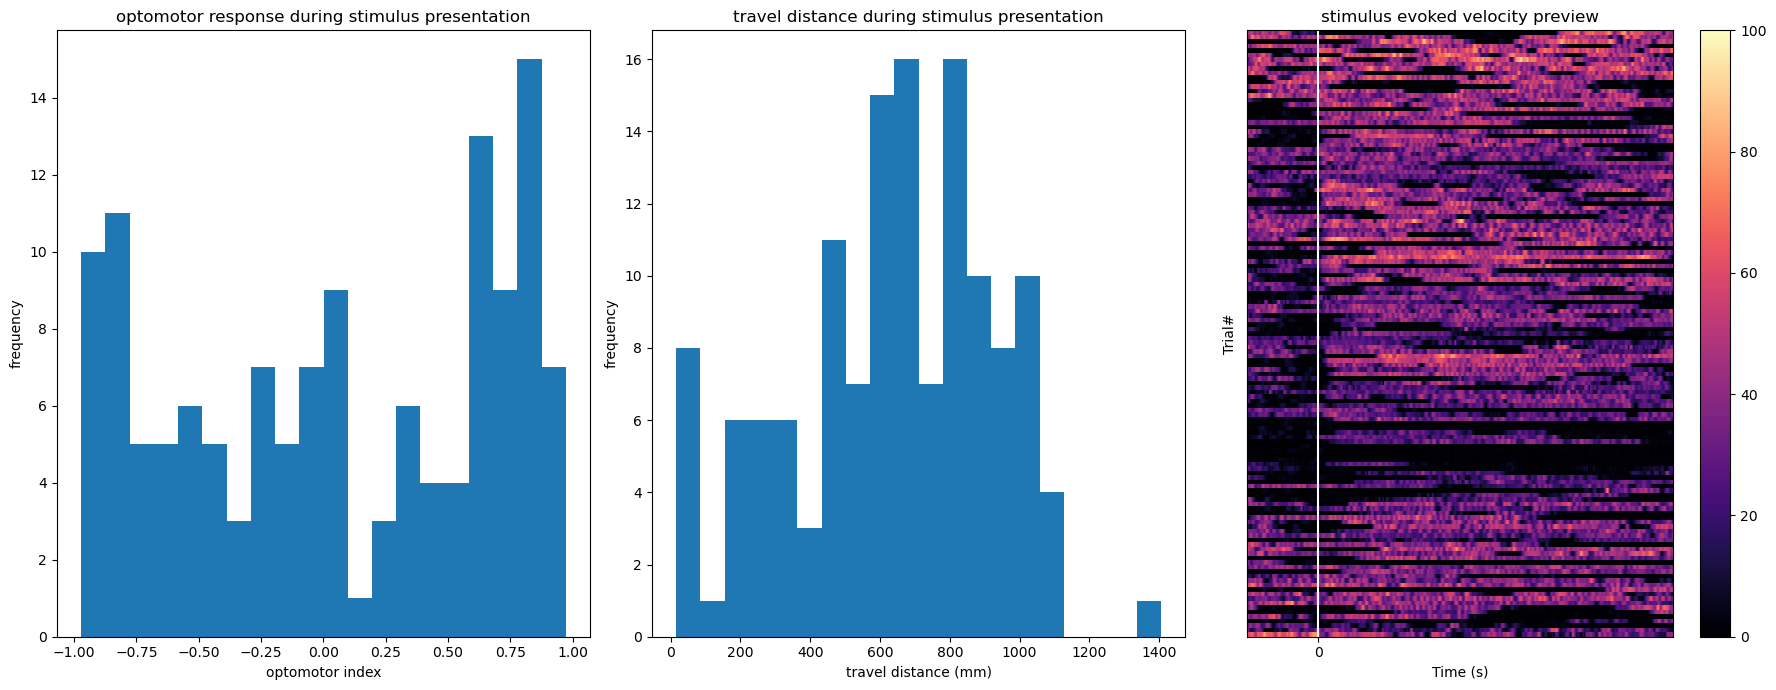

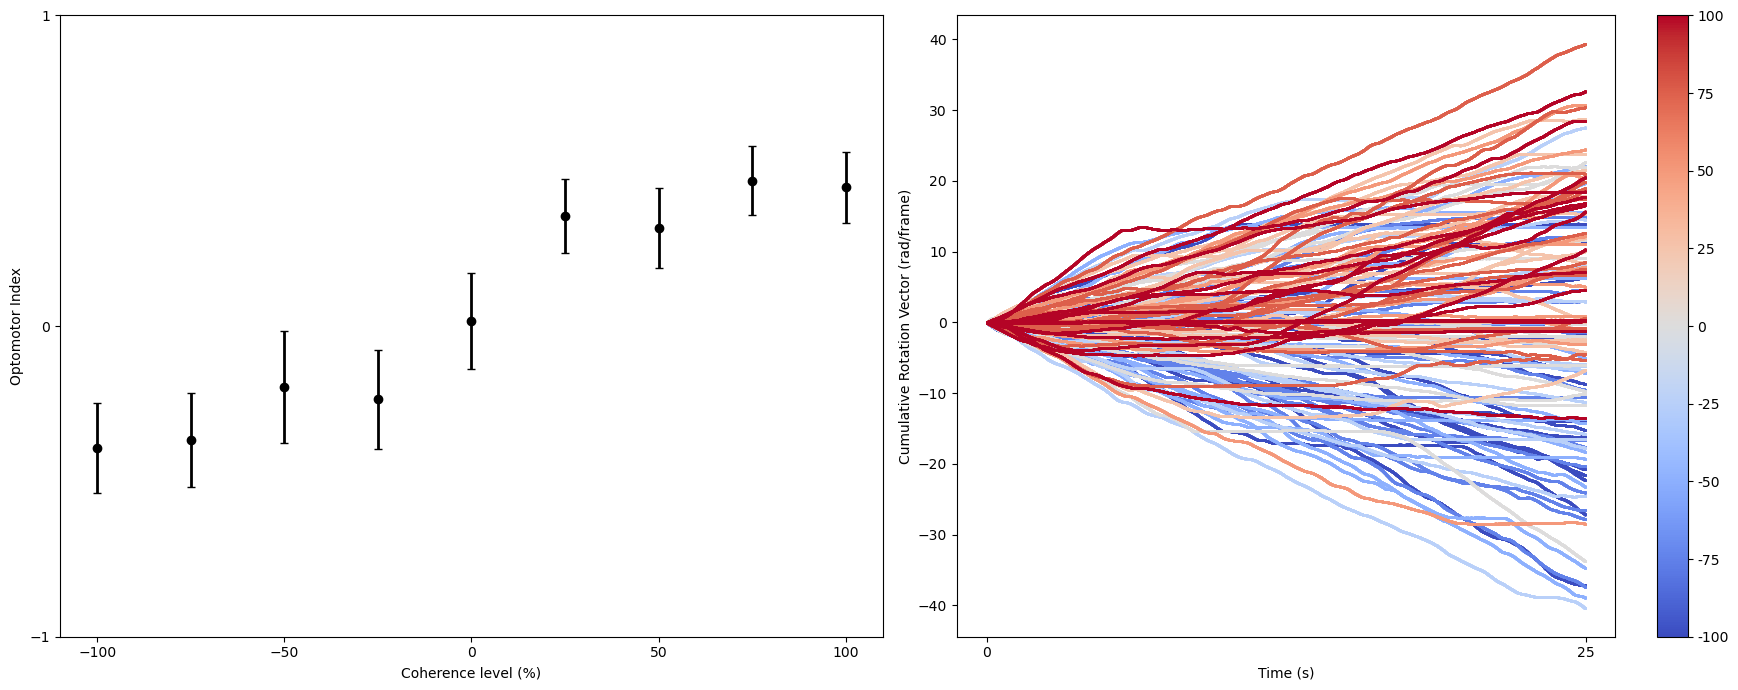

In [8]:
# because the import does not update the new version of python.
# Need to restart kernel 
output0_across_exp=[]
output1_across_exp=[]
output2_across_exp=[]
for thisDir in dir_list:
    summary,speed,travel_distance,rotation=main(thisDir,json_file)
    output0_across_exp.append(summary)
    output1_across_exp.append(speed)
    output2_across_exp.append(travel_distance)
    output2_across_exp.append(rotation)


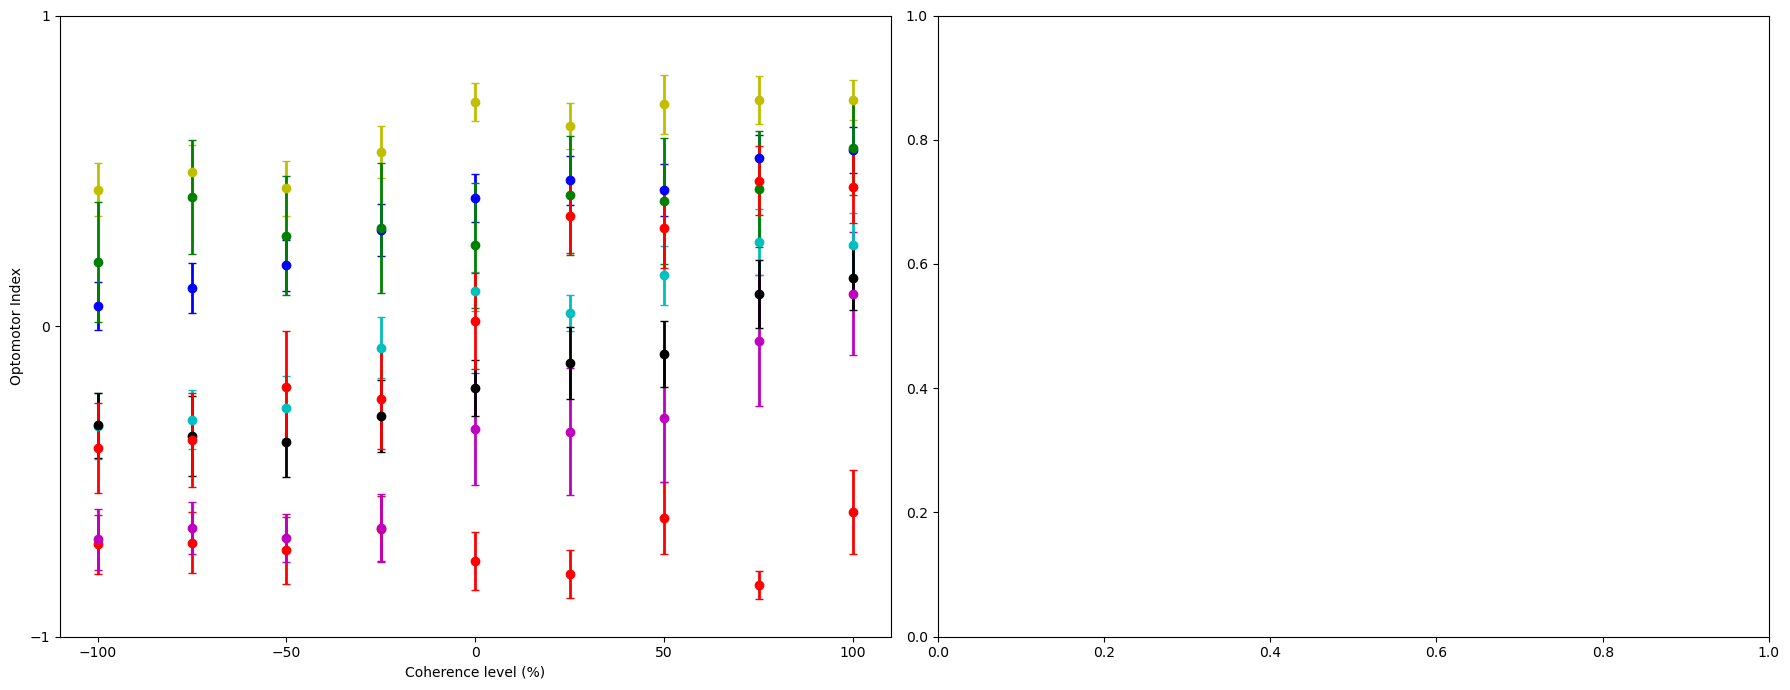

In [9]:
colormap = np.array(analysis_methods.get("graph_colour_code"))
fig2, (ax3, ax4) = plt.subplots(
    nrows=1, ncols=2, figsize=(18, 7), tight_layout=True
)
for i in range(len(output0_across_exp)):
    this_animal = output0_across_exp[i]
    tmp=this_animal.groupby("coherence_level").count()
    follow_count_coherence = tmp.index.values
    for j in range(len(this_animal.groupby("coherence_level"))):
        this_coherence=follow_count_coherence[j]
        this_response = this_animal.loc[
            this_animal["coherence_level"] == this_coherence, "opto_index"
        ].values
        # this_coherence = x_axis_value_running_trials[i]
        mean_response = np.mean(this_response, axis=0)
        sem_response = np.std(this_response, axis=0, ddof=1) / np.sqrt(
            this_response.shape[0]
        )
        ax3.errorbar(
            this_coherence,
            mean_response,
            yerr=sem_response,
            c=colormap[i],
            fmt="o",
            elinewidth=2,
            capsize=3,
        )
    ax3.set_ylim(-1, 1)
    # ax3.set_yticks([-1, 0, 1])
    ax3.set(
        yticks=[-1, 0, 1],
        ylabel="Optomotor Index",
        xticks=[100, 50, 0, -50, -100],
        xlabel="Coherence level (%)",)
    # ax4.scatter(follow_count_coherence, follow_count, c=colormap[0], marker="o")
    # ax4.set_ylim(0, 15)
    # ax4.set(
    #     yticks=[0, 15],
    #     ylabel="Follow response (count)",
    #     xticks=[100, 50, 0, -50, -100],
    #     xlabel="Coherence level (%)",
    # )